# **Task 1: Inflation betas of the major asset classes**
Assemble monthly total returns for US equities (S&P 500), nominal Treasuries, a broad commodity total-return index, gold and a REIT ETF. Regress each asset's return on monthly inflation, report the inflation beta with standard errors, rank the assets and compare the ranking with Section 4. Stretch: re-run the regressions on the unexpected part of inflation.

## Report

**Report - Core Part**

We used monthly total returns of five ETFs from Yahoo Finance: SPY (US equities), IEF (7–10y Treasuries), DBC (commodities, total return), GLD (gold) and VNQ (REITs). Inflation is the monthly change in CPI (CPIAUCSL, FRED). The sample covers March 2006 – September 2026 (245 months); October–November 2025 are missing because the October 2025 CPI was not published. For each asset we estimated the following regression with Newey-West standard errors, where β = 1 means the asset fully keeps up with inflation:

$$r_t = \alpha + \beta \cdot \pi_t + \varepsilon_t$$

| Rank | Asset | Inflation beta | SE | t-stat | Real return (ann.) |
|---|---|---|---|---|---|
| 1 | Commodities TR | 7.16 | 1.18 | 6.09 | 0.1% |
| 2 | US equities | 1.00 | 1.30 | 0.78 | 8.2% |
| 3 | REITs | 0.43 | 2.59 | 0.17 | 3.3% |
| 4 | Gold | -0.30 | 0.95 | -0.31 | 6.6% |
| 5 | Treasuries 7-10y | -1.91 | 0.41 | -4.62 | 0.4% |

Commodities are the only significant inflation hedge, while nominal Treasuries clearly lose when inflation rises. The betas of equities, REITs and gold are not significant. However, commodities earned almost no real return over 20 years, while equities earned 8.2% per year.

**Comparison with Section 4**

| Asset | Section 4 | Our result | Match? |
|---|---|---|---|
| Nominal bonds | Strongly negative | -1.91 (significant) | Yes |
| Commodities | Strongly positive | +7.16 (significant) | Yes |
| REITs | Moderately positive | +0.43 (not significant) | Same sign, too noisy |
| Gold | Positive (via real rates) | -0.30 (not significant) | No – gold follows real rates, not CPI (Section 7) |
| Equities | Low / slightly negative short-run | +1.00 (not significant) | Roughly – real beta ≈ 0 |

Section 4 implies the ranking commodities > REITs ≈ gold > equities > bonds; we find commodities > equities > REITs > gold > bonds. Both ends match, and these are the only significant results. The middle three are ordered differently, but their confidence intervals overlap, so their order is not meaningful.

**Conditional on the inflation regime**

We split the months into high inflation (CPI year-on-year above 3%, 75 months) and normal (170 months):

| Asset | High inflation | Normal | Difference (t-stat) |
|---|---|---|---|
| Commodities TR | 7.0% | -0.5% | +7.5% (0.75) |
| US equities | -1.7% | 13.8% | -15.5% (-2.20) |
| REITs | -6.7% | 11.2% | -17.9% (-2.36) |
| Gold | 4.6% | 9.4% | -4.8% (-0.52) |
| Treasuries 7-10y | -3.0% | 2.3% | -5.3% (-1.29) |

Commodities were the only asset with a positive real return during high inflation. The cost is a slightly negative real return in normal months, which make up 70% of the sample. Equities and REITs lost significantly in real terms during high inflation, which the full-sample beta hides. The result is uncertain because of the small sample (Section 7): the 75 high-inflation months come from only six episodes, and 2021–2024 alone accounts for half of them.

**Report - Stretch Part**

Expected inflation is a real-time AR(1) forecast estimated on the previous 120 months; the surprise is actual minus expected inflation.

| Asset | Beta (total) | Beta (surprise) |
|---|---|---|
| Commodities TR | 7.16 | 8.29 |
| US equities | 1.00 | 1.39 |
| REITs | 0.43 | 1.23 |
| Gold | -0.30 | 0.57 |
| Treasuries 7-10y | -1.91 | -1.99 |

All betas become larger against the surprise, which is consistent with the idea that only unexpected inflation moves prices (Sections 1 and 7). The differences are small (within one standard error), however, because the AR(1) model forecasts very little of monthly inflation.

In [11]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import yfinance as yf

BASE = Path.cwd()
OUT = BASE / "data"
OUT.mkdir(parents=True, exist_ok=True)
print(f"Outputs will be saved in: {OUT}")

ASSETS = {"SPY": "US equities", "IEF": "Treasuries 7-10y", "DBC": "Commodities TR",
          "GLD": "Gold", "VNQ": "REITs"}
NW_LAGS = 6      # Newey-West lags
ROLL_AR = 120    # months of history used for each real-time AR(1) inflation forecast
HIGH_INFL = 0.03 # high-inflation month = CPI year-on-year above 3%
                 # (robustness check: top quintile of CPI year-on-year)

Outputs will be saved in: /Users/macc/Documents/asset-allocation-26-27/Assignment4/Task1/data


## 1. Download data

In [4]:
def fred(series_id):
    """Monthly FRED series via the public CSV endpoint (no API key needed)."""
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    s = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
    s.index = s.index.to_period("M").to_timestamp()
    return s.rename(series_id)
 
 
def yahoo_monthly_returns(tickers):
    """Monthly total returns (decimals) from dividend-adjusted closing prices."""
    px = yf.download(list(tickers), start="1990-01-01", auto_adjust=True,
                     progress=False)["Close"]
    px = px.resample("ME").last()
    px.index = px.index.to_period("M").to_timestamp()
    return px.pct_change(fill_method=None)
 
 
rets = yahoo_monthly_returns(ASSETS).rename(columns=ASSETS)
cpi = fred("CPIAUCSL")
infl_all = cpi.pct_change().rename("infl")               # full history, used for AR(1)
infl_yoy = cpi.pct_change(12, fill_method=None).rename("infl_yoy")   # used for regimes
 
df = rets.join([infl_all, infl_yoy], how="inner").dropna()   # common sample
df.to_csv(OUT / "data_monthly.csv")
print(f"Sample: {df.index[0]:%Y-%m} to {df.index[-1]:%Y-%m}, {len(df)} months")

Sample: 2006-03 to 2026-09, 245 months


## 2. Expected vs unexpected inflation (stretch)

In [6]:
def realtime_ar1_forecast(infl, window=ROLL_AR):
    """Forecast of infl_t from an AR(1) fitted only on months t-window .. t-1."""
    x = infl.dropna()
    fc = pd.Series(np.nan, index=x.index)
    for i in range(window + 1, len(x)):
        hist = x.iloc[i - window - 1:i]
        slope, const = np.polyfit(hist.shift(1).iloc[1:], hist.iloc[1:], 1)
        fc.iloc[i] = const + slope * x.iloc[i - 1]
    return fc
 
 
df["infl_expected"] = realtime_ar1_forecast(infl_all).reindex(df.index)
df["infl_surprise"] = df["infl"] - df["infl_expected"]

## 3. Inflation betas

In [7]:
def ols(y, x):
    """OLS of y on a constant and x, Newey-West standard errors."""
    m = sm.OLS(y, sm.add_constant(x), missing="drop").fit(
        cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    return m.params.iloc[1], m.bse.iloc[1], m.tvalues.iloc[1], m.pvalues.iloc[1], m.rsquared
 
 
rows = {}
for a in ASSETS.values():
    b, se, t, p, r2 = ols(df[a], df["infl"])
    bs, ses, ts, _, r2s = ols(df[a], df["infl_surprise"])
    real = (1 + df[a]) / (1 + df["infl"]) - 1
    rows[a] = {
        "beta": b, "se (NW)": se, "t": t, "p": p, "R2": r2,
        "beta surprise": bs, "se surprise": ses, "t surprise": ts, "R2 surprise": r2s,
        "real return (ann.)": (1 + real).prod() ** (12 / len(real)) - 1,
        "real vol (ann.)": real.std() * np.sqrt(12),
    }
 
res = pd.DataFrame(rows).T.sort_values("beta", ascending=False)
res.insert(0, "rank", range(1, len(res) + 1))
res.to_csv(OUT / "inflation_betas.csv")
 
report = (
    f"=== Inflation betas, {df.index[0]:%Y-%m} to {df.index[-1]:%Y-%m}, N = {len(df)} ===\n"
    f"Monthly return regressed on monthly CPI inflation; beta = 1 means full hedge.\n"
    f"'surprise' = inflation minus real-time AR(1) forecast ({ROLL_AR}-month window).\n\n"
    f"{res.round(3).to_string()}\n\n"
    f"Inflation: mean {df['infl'].mean() * 12:.2%} p.a., monthly std {df['infl'].std():.2%}; "
    f"surprise monthly std {df['infl_surprise'].std():.2%}"
)
print(report)
(OUT / "results.txt").write_text(report)

=== Inflation betas, 2006-03 to 2026-09, N = 245 ===
Monthly return regressed on monthly CPI inflation; beta = 1 means full hedge.
'surprise' = inflation minus real-time AR(1) forecast (120-month window).

                  rank   beta  se (NW)      t      p     R2  beta surprise  se surprise  t surprise  R2 surprise  real return (ann.)  real vol (ann.)
Commodities TR       1  7.162    1.176  6.091  0.000  0.171          8.285        1.651       5.017        0.178               0.001            0.184
US equities          2  1.003    1.295  0.775  0.438  0.005          1.386        1.480       0.936        0.008               0.082            0.151
REITs                3  0.428    2.594  0.165  0.869  0.000          1.226        3.229       0.380        0.003               0.033            0.219
Gold                 4 -0.296    0.947 -0.313  0.754  0.000          0.574        1.121       0.512        0.001               0.066            0.175
Treasuries 7-10y     5 -1.907    0.413 -4.62

1180

In [8]:
# %% 3b. Conditional on the inflation regime ---------------------------------
def regime_table(is_high):
    """Per asset and state: real return, real vol, inflation beta within the state."""
    rows = {}
    for a in ASSETS.values():
        real = (1 + df[a]) / (1 + df["infl"]) - 1
        for state, mask in [("High inflation", is_high), ("Normal", ~is_high)]:
            b, se, t, _, _ = ols(df.loc[mask, a], df.loc[mask, "infl"])
            rows[(a, state)] = {
                "months": int(mask.sum()),
                "mean real return (ann.)": real[mask].mean() * 12,
                "real vol (ann.)": real[mask].std() * np.sqrt(12),
                "beta in state": b, "se (NW)": se, "t": t,
            }
        # does the mean real return differ between the states? (dummy regression, NW)
        d = ols(real, is_high.astype(float))
        rows[(a, "High - Normal")] = {"mean real return (ann.)": d[0] * 12, "t": d[2]}
    return pd.DataFrame(rows).T[["months", "mean real return (ann.)", "real vol (ann.)",
                                 "beta in state", "se (NW)", "t"]]
 
 
regimes = {
    f"CPI YoY > {HIGH_INFL:.0%}": df["infl_yoy"] > HIGH_INFL,
    "CPI YoY in top quintile": df["infl_yoy"] > df["infl_yoy"].quantile(0.8),
}
reg_report = []
for name, is_high in regimes.items():
    tbl = regime_table(is_high)
    tbl.to_csv(OUT / f"regime_{'threshold' if '>' in name else 'quintile'}.csv")
    # list the high-inflation episodes so the small sample is visible
    starts = df.index[is_high & ~is_high.shift(1, fill_value=False)]
    ends = df.index[is_high & ~is_high.shift(-1, fill_value=False)]
    episodes = ", ".join(f"{a:%Y-%m}–{b:%Y-%m}" for a, b in zip(starts, ends))
    reg_report.append(
        f"\n=== Conditional on inflation regime: high = {name} "
        f"({int(is_high.sum())} of {len(df)} months) ===\n"
        f"High-inflation episodes: {episodes}\n"
        f"'High - Normal' row: difference in mean real return, NW t-stat of the difference\n\n"
        f"{tbl.round(3).to_string(na_rep='')}")
print("\n".join(reg_report))
with open(OUT / "results.txt", "a") as f:
    f.write("\n" + "\n".join(reg_report))
 
regime_main = regimes[f"CPI YoY > {HIGH_INFL:.0%}"]
 


=== Conditional on inflation regime: high = CPI YoY > 3% (75 of 245 months) ===
High-inflation episodes: 2006-03–2006-08, 2007-10–2008-10, 2011-04–2012-01, 2021-04–2024-05, 2025-09–2025-09, 2026-03–2026-09
'High - Normal' row: difference in mean real return, NW t-stat of the difference

                                 months  mean real return (ann.)  real vol (ann.)  beta in state  se (NW)      t
US equities      High inflation    75.0                   -0.017            0.176          1.427    2.736  0.522
                 Normal           170.0                    0.138            0.137          1.933    1.005  1.923
                 High - Normal                            -0.155                                          -2.204
Treasuries 7-10y High inflation    75.0                   -0.030            0.077         -0.511    0.571 -0.895
                 Normal           170.0                    0.023            0.067         -3.002    0.540 -5.564
                 High - Normal   

## 4. Charts

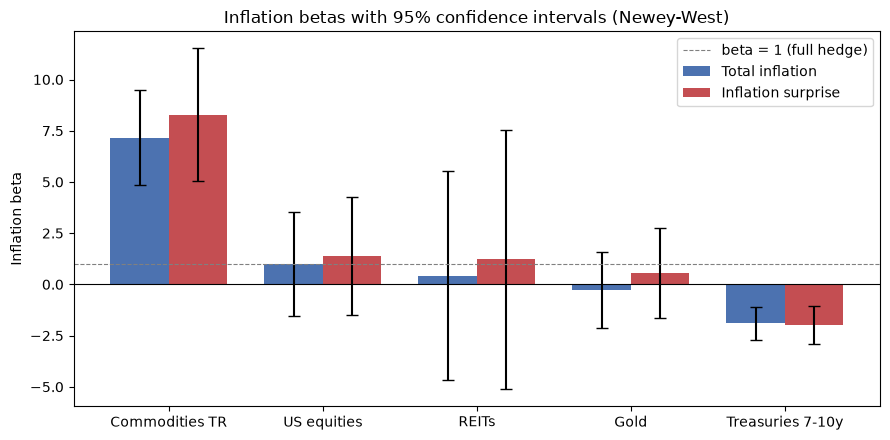

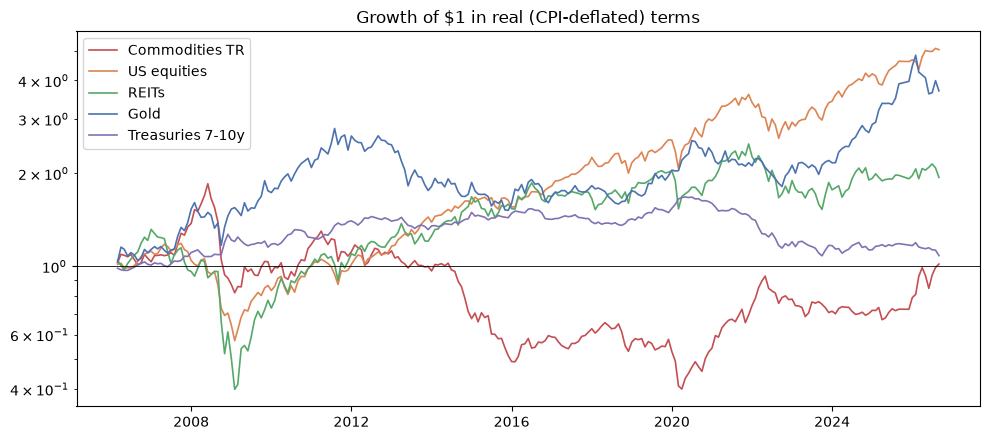

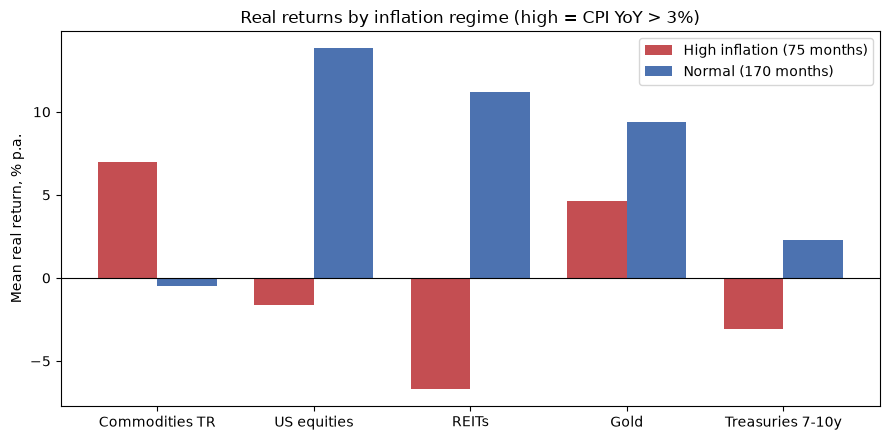


Done. Outputs in /Users/macc/Documents/asset-allocation-26-27/Assignment4/Task1/data


In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(res))
w = 0.38
ax.bar(x - w / 2, res["beta"], w, yerr=1.96 * res["se (NW)"], capsize=4,
       color="#4c72b0", label="Total inflation")
ax.bar(x + w / 2, res["beta surprise"], w, yerr=1.96 * res["se surprise"], capsize=4,
       color="#c44e52", label="Inflation surprise")
ax.axhline(0, color="black", lw=0.8)
ax.axhline(1, color="grey", lw=0.8, ls="--", label="beta = 1 (full hedge)")
ax.set_xticks(x)
ax.set_xticklabels(res.index)
ax.set_ylabel("Inflation beta")
ax.set_title("Inflation betas with 95% confidence intervals (Newey-West)")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "inflation_betas.png", dpi=150)
plt.show()
 
fig, ax = plt.subplots(figsize=(10, 4.5))
for a, c in zip(res.index, ["#c44e52", "#dd8452", "#55a868", "#4c72b0", "#8172b3"]):
    real = (1 + df[a]) / (1 + df["infl"]) - 1
    ax.plot(df.index, (1 + real).cumprod(), label=a, color=c, lw=1.2)
ax.axhline(1, color="black", lw=0.6)
ax.set_yscale("log")
ax.set_title("Growth of $1 in real (CPI-deflated) terms")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "real_wealth.png", dpi=150)
plt.show()
 
tbl = regime_table(regime_main)
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(ASSETS))
names = list(res.index)
for k, (state, c) in enumerate([("High inflation", "#c44e52"), ("Normal", "#4c72b0")]):
    vals = [tbl.loc[(a, state), "mean real return (ann.)"] * 100 for a in names]
    ax.bar(x + (k - 0.5) * 0.38, vals, 0.38, color=c,
           label=f"{state} ({int(tbl.loc[(names[0], state), 'months'])} months)")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("Mean real return, % p.a.")
ax.set_title(f"Real returns by inflation regime (high = CPI YoY > {HIGH_INFL:.0%})")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "real_return_by_regime.png", dpi=150)
plt.show()
 
print(f"\nDone. Outputs in {OUT}")